# Olist: monthly orders chart

## Goal
Plot monthly valid orders in one chart that makes the missing month and the sparse edge months visible.

## Setup
Load orders and compute `monthly_orders` as in [02-monthly-orders](02-monthly-orders.ipynb).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Project folder = the nearest parent that contains data/raw
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
DATA_DIR = ROOT / "data" / "raw"
import matplotlib.pyplot as plt

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
orders["purchase_ts"] = pd.to_datetime(orders["order_purchase_timestamp"], errors="coerce")
valid_orders = orders[~orders["order_status"].isin(["canceled", "unavailable"])].copy()
valid_orders["purchase_month"] = valid_orders["purchase_ts"].dt.to_period("M")
monthly_orders = valid_orders.groupby("purchase_month")["order_id"].nunique()
print("Months:", len(monthly_orders), "| total orders:", monthly_orders.sum())

Months: 24 | total orders: 98207


## Design choices
- **Question**: how many valid orders were placed each month, how does the trend move, and where is the peak?
- **Axes**: purchase month on the x-axis; valid orders per month on the y-axis (canceled and unavailable excluded, distinct `order_id`).
- **Missing month (2016-11)**: the index is completed to consecutive months and the gap is left empty, so the line breaks there and is labelled "no data". It is not filled with 0, which would read as "nobody ordered" when the month is simply absent from the data.
- **Sparse months** (2016-09, 2016-12 and 2018-09 have single-digit orders): kept, greyed out and labelled. Removing them would suggest the data starts in 2017-01. The trend is read only inside the observation period 2017-01 to 2018-08, which is shaded.
- **Title**: states the object (valid orders), the unit (orders per month) and the time range.

## Chart

Missing months: ['2016-11']


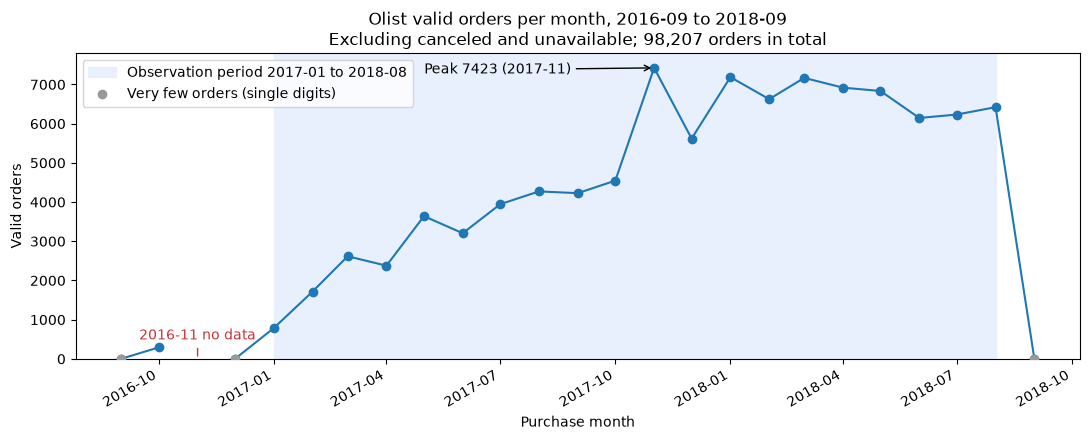

In [2]:
# 1. Complete the index to consecutive months: 2016-11 appears with an empty value and breaks the line
all_months = pd.period_range(monthly_orders.index.min(), monthly_orders.index.max(), freq="M")
full = monthly_orders.reindex(all_months)
print("Missing months:", [str(m) for m in full.index[full.isna()]])

# 2. Sparse months (single-digit orders) and the observation period
sparse = full[full < 10]
core = full["2017-01":"2018-08"]

x = full.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4.5))

ax.axvspan(core.index.min().to_timestamp(), core.index.max().to_timestamp(), color="#e8f0fe", label="Observation period 2017-01 to 2018-08")
ax.plot(x, full.values, marker="o", color="#1f77b4")                       # breaks automatically at empty values
ax.scatter(sparse.index.to_timestamp(), sparse.values, color="#999999", zorder=3, label="Very few orders (single digits)")

# 3. Annotations: missing month and peak
for m in full.index[full.isna()]:
    ax.annotate(f"{m} no data", (m.to_timestamp(), 0), xytext=(0, 14), textcoords="offset points",
                ha="center", color="#cc3333", arrowprops=dict(arrowstyle="-", color="#cc3333"))
peak = full.idxmax()
ax.annotate(f"Peak {int(full.max())} ({peak})", (peak.to_timestamp(), full.max()),
            xytext=(-60, -4), textcoords="offset points", ha="right", arrowprops=dict(arrowstyle="->"))

# 4. Title with object, unit and time range; axis labels with units
ax.set_title(f"Olist valid orders per month, {full.index.min()} to {full.index.max()}\nExcluding canceled and unavailable; {int(monthly_orders.sum()):,} orders in total")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Valid orders")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Findings
- Orders rise through 2017 to a peak of 7,423 in 2017-11, then stay between roughly 6,100 and 7,200 a month from 2018-01 to 2018-08.
- 2016-11 is absent from the data; 2016-09, 2016-12 and 2018-09 have one or two orders each and say nothing about the trend.
- The chart shows what happened, not why: the reason for the 2017-11 peak is not in the data.